In [3]:
import pandas as pd
df = pd.read_csv("city_day.csv")
print(df[df["City"] == "Kolkata"].head())

          City        Date  PM2.5   PM10    NO    NO2    NOx   NH3    CO  \
19032  Kolkata  2018-04-10  34.38  57.00   NaN  40.97    NaN  2.52  1.00   
19033  Kolkata  2018-04-11  29.00  50.87  3.26  34.03  45.29  3.59  0.98   
19034  Kolkata  2018-04-12  21.70  43.04  3.49  39.49  42.54  3.77  0.73   
19035  Kolkata  2018-04-13  23.09  46.49  3.69  33.03  36.72  3.88  0.98   
19036  Kolkata  2018-04-14  21.56  42.10  2.81  26.62  29.43  4.22  1.00   

         SO2     O3  Benzene  Toluene  Xylene   AQI    AQI_Bucket  
19032  25.46    NaN      NaN      NaN     NaN   NaN           NaN  
19033  10.32  30.99     4.64     0.88     NaN  73.0  Satisfactory  
19034    NaN  43.72     5.33     1.76     NaN  60.0  Satisfactory  
19035    NaN  41.65     6.78     2.23     NaN  74.0  Satisfactory  
19036    NaN  44.07     5.09     2.33     NaN  83.0  Satisfactory  


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_style("whitegrid")

In [3]:
#Kolkata data load
df = pd.read_csv("city_day.csv", parse_dates=["Date"])
df = df[df["City"] == "Kolkata"].sort_values("Date").reset_index(drop=True)
print(df.shape)
print(df.isnull().sum())
df.describe()

(814, 16)
City            0
Date            0
PM2.5          55
PM10           55
NO             26
NO2            25
NOx             1
NH3             0
CO              0
SO2            62
O3             50
Benzene         1
Toluene         1
Xylene        420
AQI            60
AQI_Bucket     60
dtype: int64


,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,814,759.000000,759.000000,788.000000,789.000000,813.000000,814.000000,814.000000,752.000000,764.000000,813.000000,813.000000,394.000000,754.000000
mean,2019-05-21 12:00:00,64.362833,115.629499,26.846916,40.396210,63.365695,18.370381,0.799251,8.392101,30.663233,10.869815,15.395203,2.566294,140.566313
min,2018-04-10 00:00:00,3.560000,7.120000,0.470000,5.080000,8.070000,1.520000,0.000000,0.970000,4.150000,0.370000,0.000000,0.180000,26.000000
25%,2018-10-30 06:00:00,21.200000,43.155000,4.490000,18.290000,24.220000,9.522500,0.410000,3.360000,21.705000,2.400000,7.010000,1.040000,60.000000
50%,2019-05-21 12:00:00,43.550000,81.770000,8.165000,32.560000,40.140000,13.550000,0.680000,6.840000,30.060000,5.890000,10.330000,2.480000,94.000000
75%,2019-12-10 18:00:00,89.705000,167.555000,34.285000,54.740000,90.110000,25.552500,1.160000,12.460000,38.032500,18.140000,20.500000,3.390000,207.000000
max,2020-07-01 00:00:00,304.740000,469.320000,197.730000,150.010000,293.100000,85.390000,3.040000,81.590000,81.120000,64.440000,76.040000,13.540000,475.000000
std,NaN,58.381092,92.485062,36.104748,28.803024,54.785173,12.566398,0.511176,6.453944,12.186248,10.626216,13.105523,1.947499,104.492533


In [4]:
#Preprocessing
features = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
df = df.set_index("Date")
df = df[features + ["AQI"]]

# Missing value: time-wise interpolation
df = df.interpolate(method="time", limit_direction="both")
df = df.dropna()

# Calendar features
df["month"] = df.index.month
df["dayofweek"] = df.index.dayofweek
df["season"] = df["month"].map({12:0,1:0,2:0, 3:1,4:1,5:1, 6:2,7:2,8:2,9:2, 10:3,11:3})
# 0=Winter, 1=Summer, 2=Monsoon, 3=Post-monsoon

# Target: kal-ker AQI
df["AQI_next"] = df["AQI"].shift(-1)
df = df.dropna()

print(df.shape)
df.head()

(813, 14)


C:\Users\hi\AppData\Local\Temp\ipykernel_6064\4152104751.py:12: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df["dayofweek"] = df.index.dayofweek


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI,month,dayofweek,season,AQI_next
Date,,,,,,,,,,,,,,
2018-04-10,34.38,57.00,3.26,40.97,45.29,2.52,1.00,25.460000,30.99,73.0,4,1,1,73.0
2018-04-11,29.00,50.87,3.26,34.03,45.29,3.59,0.98,10.320000,30.99,73.0,4,2,1,60.0
2018-04-12,21.70,43.04,3.49,39.49,42.54,3.77,0.73,10.255263,43.72,60.0,4,3,1,74.0
2018-04-13,23.09,46.49,3.69,33.03,36.72,3.88,0.98,10.190526,41.65,74.0,4,4,1,83.0
2018-04-14,21.56,42.10,2.81,26.62,29.43,4.22,1.00,10.125789,44.07,83.0,4,5,1,95.0


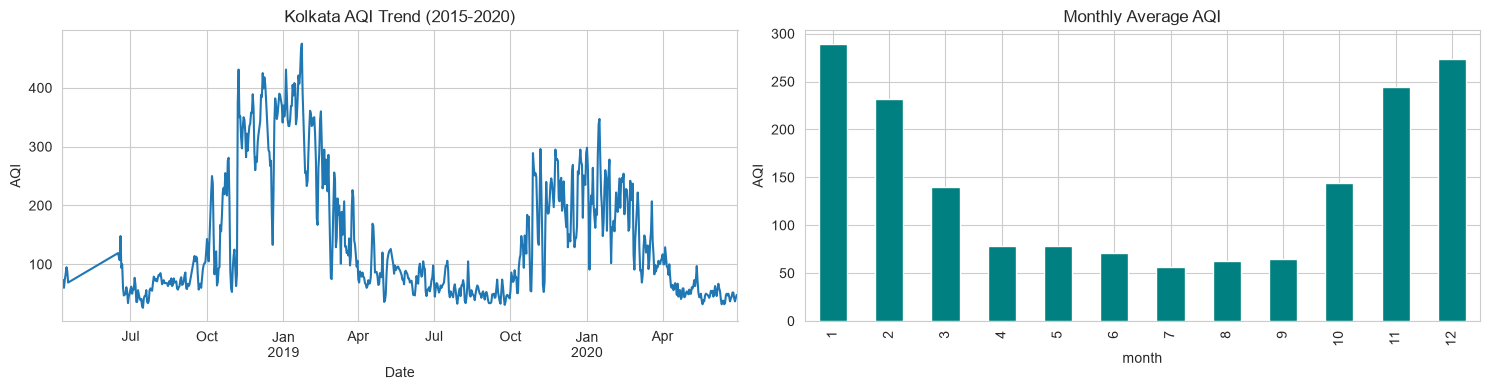

In [ ]:
#EDA, trend ar seasonal pattern
fig, ax = plt.subplots(1, 2, figsize=(15, 4))

df["AQI"].plot(ax=ax[0], title="Kolkata AQI Trend (2015-2020)")
ax[0].set_ylabel("AQI")

df.groupby("month")["AQI"].mean().plot(kind="bar", ax=ax[1], color="teal",
                                       title="Monthly Average AQI")
ax[1].set_ylabel("AQI")
plt.tight_layout()
plt.savefig("../eda_trend_monthly.png", dpi=150)
plt.show()

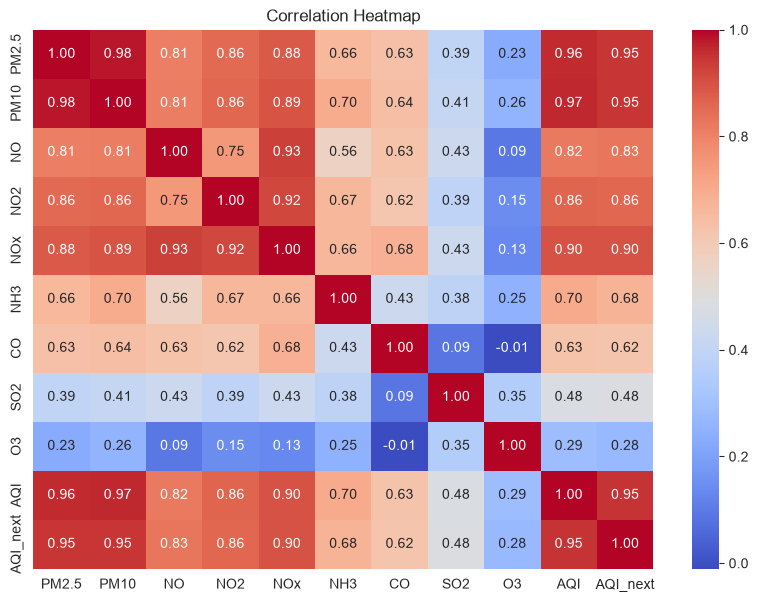

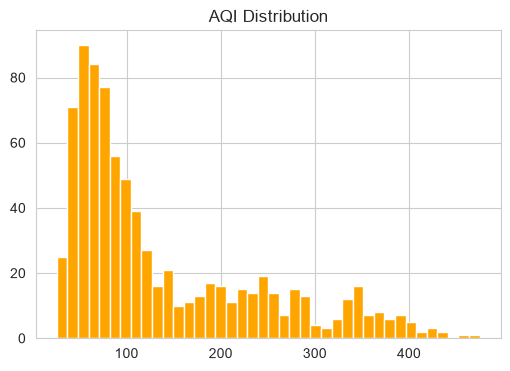

In [6]:
#EDA, correlation ar distribution
plt.figure(figsize=(10, 7))
sns.heatmap(df[features + ["AQI", "AQI_next"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("../eda_correlation.png", dpi=150)
plt.show()

df["AQI"].hist(bins=40, figsize=(6,4), color="orange")
plt.title("AQI Distribution")
plt.show()

In [7]:
#Train-test split (time based)
X_cols = features + ["AQI", "month", "dayofweek", "season"]
X = df[X_cols]
y = df["AQI_next"]

split = int(len(df) * 0.8)   # prothom 80% train, shesh 20% test
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (650, 13) Test: (163, 13)


In [8]:
#three models train
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42),
}

results, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    preds[name] = p
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, p),
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "R2": r2_score(y_test, p),
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,MAE,RMSE,R2
0,Linear Regression,14.714,21.197,0.902
1,Random Forest,13.311,18.785,0.923
2,XGBoost,14.800,19.723,0.915


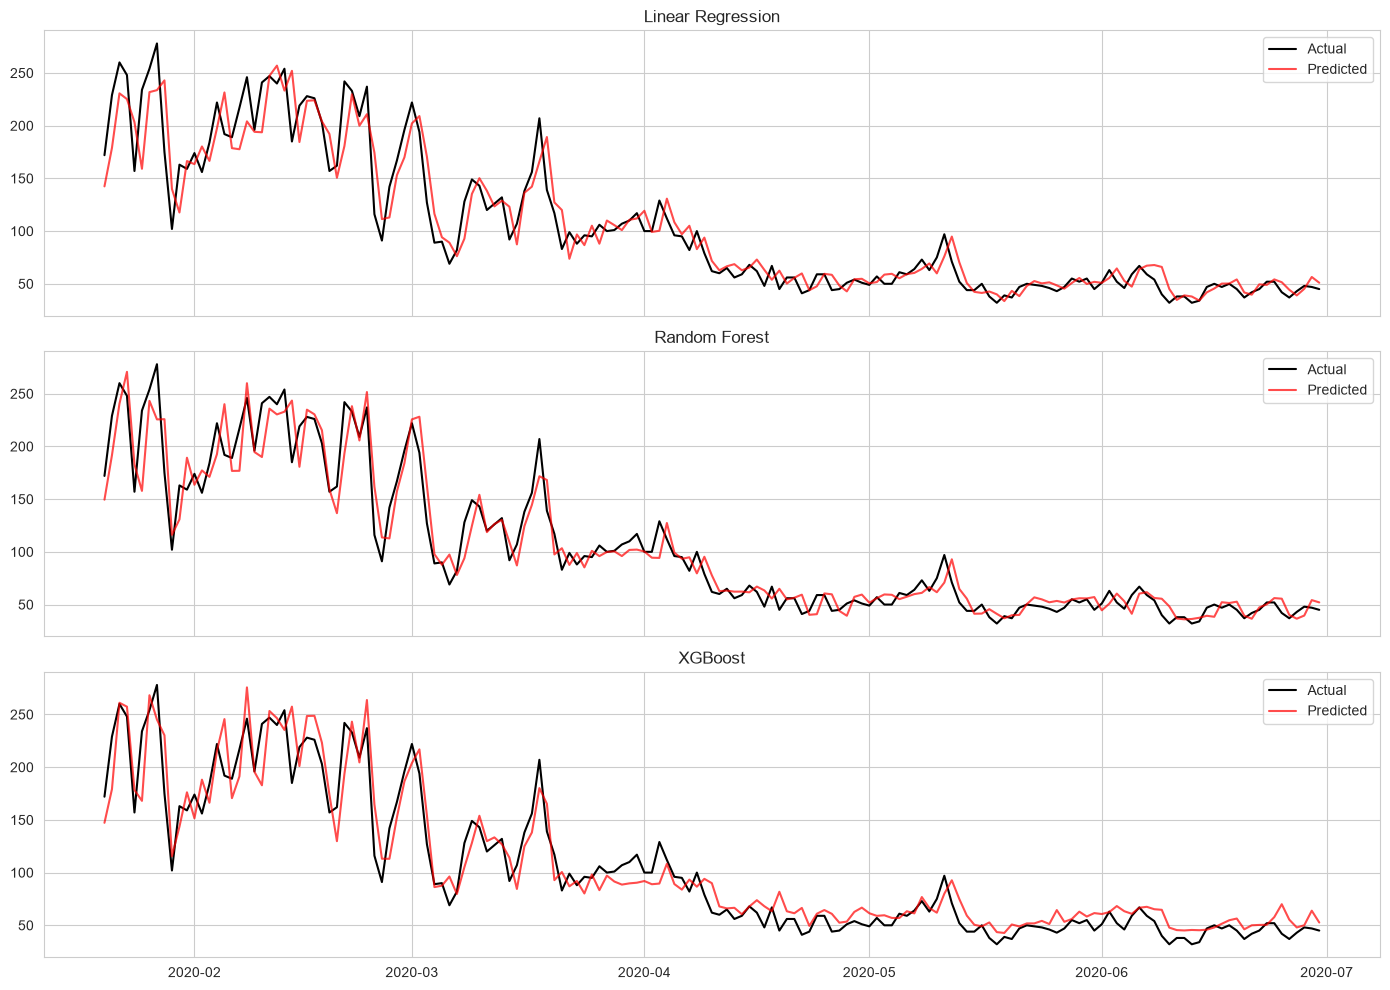

In [9]:
#Comparison, Actual vs Predicted
results_df.to_csv("../model_comparison.csv", index=False)

fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for i, name in enumerate(models):
    ax[i].plot(y_test.index, y_test.values, label="Actual", color="black")
    ax[i].plot(y_test.index, preds[name], label="Predicted", color="red", alpha=0.7)
    ax[i].set_title(name)
    ax[i].legend()
plt.tight_layout()
plt.savefig("../actual_vs_predicted.png", dpi=150)
plt.show()

In [14]:
#Best model save
best_name = results_df.sort_values("RMSE").iloc[0]["Model"]
print("Best model:", best_name)

os.makedirs("../model", exist_ok=True)
joblib.dump(models[best_name], "../model/best_model.pkl")
joblib.dump(X_cols, "../model/columns.pkl")

Best model: Random Forest


['../model/columns.pkl']

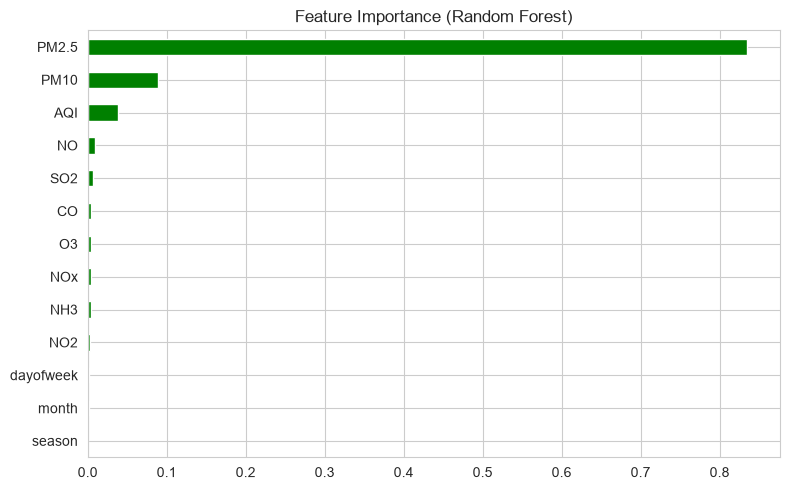

In [15]:
#Feature importance
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X_cols).sort_values()
imp.plot(kind="barh", figsize=(8,5), color="green", title="Feature Importance (Random Forest)")
plt.tight_layout()
plt.savefig("../feature_importance.png", dpi=150)
plt.show()

In [11]:
# Baseline: "kal er AQI = aj er AQI"
base_pred = X_test["AQI"].values
base = {
    "Model": "Baseline (Persistence)",
    "MAE": mean_absolute_error(y_test, base_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, base_pred)),
    "R2": r2_score(y_test, base_pred),
}
results_df = pd.concat([pd.DataFrame([base]).round(3), results_df], ignore_index=True)
results_df.to_csv("../model_comparison.csv", index=False)
results_df

,Model,MAE,RMSE,R2
0,Baseline (Persistence),17.393,27.017,0.841
1,Linear Regression,14.714,21.197,0.902
2,Random Forest,13.311,18.785,0.923
3,XGBoost,14.800,19.723,0.915


In [12]:
import os
print("Current folder:", os.getcwd())
print("Model saved at:", os.path.abspath("../model/best_model.pkl"))
print("Exists?", os.path.exists("../model/best_model.pkl"))

Current folder: c:\Users\hi\OneDrive\Documents\kolkata-aqi-prediction
Model saved at: c:\Users\hi\OneDrive\Documents\model\best_model.pkl
Exists? True


In [13]:
root = r"C:\Users\hi\OneDrive\Documents\kolkata-aqi-prediction"
os.makedirs(os.path.join(root, "model"), exist_ok=True)
joblib.dump(models[best_name], os.path.join(root, "model", "best_model.pkl"))
joblib.dump(X_cols, os.path.join(root, "model", "columns.pkl"))
print("Saved!")

Saved!
